In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

sns.set_theme(style="whitegrid", palette="deep")

**Load the dataset**

In [4]:
sales = pd.read_csv(
    SALES_FILE,
    parse_dates=[
        "transaction_date",
        "sales_month_start",
        "sales_week_start"
    ],
    low_memory=False
)

display(sales.head())

,sales_row_id,transaction_date,sales_type,is_return,transaction_type,return_reason,supplier,product_no,product_description,product_division,product_category,product_subcategory,product_segment,store_id,sales_channel,quantity_sold,sales_amount,cogs,gross_profit,transaction_count,product_store_key,sales_year,sales_quarter,sales_month_number,sales_month,sales_week,sales_day,sales_month_start,sales_week_start,sales_year_month,sales_year_month_sort
0,1,2025-09-01,Full Price,0,Sale,NaN,Vendor 0169,PROD-139867,PROD-100449 SEG-500065 Scholar Footwear Trailb...,Scholar Footwear,Scholar Footwear Trailblazer,Scholar Footwear Trailblazer Equilibrium,SEG-500065 Scholar Footwear Trailblazer Equili...,STR-1006,Channel Alpha,1,115.00,52.31,62.69,1,PROD-139867|STR-1006,2025,3,9,September,36,Monday,2025-09-01,2025-08-31,2025-09,202509
1,2,2025-09-07,Full Price,0,Sale,NaN,Vendor 0166,PROD-100449,PROD-100825 SEG-500112 Heritage Footwear Fligh...,Femme Footwear,Femme Footwear Flight Classic,Femme Footwear Flight Classic Varied,SEG-500112 Heritage Footwear Flight Classic Ze...,STR-1198,Channel Alpha,1,115.00,58.47,56.53,1,PROD-100449|STR-1198,2025,3,9,September,37,Sunday,2025-09-01,2025-09-07,2025-09,202509
2,3,2025-08-06,Promo,0,Sale,NaN,Vendor 0169,PROD-153623,PROD-148813 SEG-511388 Scholar Footwear Trailb...,Scholar Footwear,Scholar Footwear Trailblazer,Scholar Footwear Trailblazer Equilibrium,SEG-511388 Scholar Footwear Trailblazer Equili...,STR-1157,Channel Alpha,1,79.99,43.76,36.23,1,PROD-153623|STR-1157,2025,3,8,August,32,Wednesday,2025-08-01,2025-08-03,2025-08,202508
3,4,2025-08-31,Full Price,0,Sale,NaN,Vendor 0246,PROD-140876,PROD-100419 SEG-500063 Scholar Footwear Boot C...,Scholar Footwear,Scholar Footwear Boot Collection,Scholar Footwear Boot Collection Woodland,SEG-500063 Scholar Footwear Boot Collection Wo...,STR-1234,Channel Alpha,1,110.00,50.60,59.40,1,PROD-140876|STR-1234,2025,3,8,August,36,Sunday,2025-08-01,2025-08-31,2025-08,202508
4,5,2026-03-22,Full Price,0,Sale,NaN,Vendor 0169,PROD-166113,PROD-149345 SEG-511444 Femme Footwear Trailbla...,Femme Footwear,Femme Footwear Trailblazer,Femme Footwear Trailblazer Equilibrium,SEG-511444 Femme Footwear Trailblazer Equilibrium,STR-1157,Channel Alpha,1,160.00,77.95,82.05,1,PROD-166113|STR-1157,2026,1,3,March,13,Sunday,2026-03-01,2026-03-22,2026-03,202603


In [5]:
print(f"Rows: {len(sales):,}")
print(f"Products: {sales['product_no'].nunique():,}")
print(
    "Date range:",
    sales["transaction_date"].min().date(),
    "to",
    sales["transaction_date"].max().date()
)

Rows: 125,751
Products: 2,326
Date range: 2025-06-01 to 2026-04-24


**Verify required columns**

In [6]:
required_columns = [
    "product_no",
    "product_description",
    "product_division",
    "product_category",
    "product_subcategory",
    "product_segment",
    "sales_month_start",
    "transaction_type",
    "quantity_sold",
    "sales_amount",
    "gross_profit"
]

missing_columns = [
    column
    for column in required_columns
    if column not in sales.columns
]

print("Missing columns:", missing_columns)

Missing columns: []


**Build ABC classification**

In [7]:
#Aggregate product performance 
product_performance = (
    sales.groupby("product_no", as_index=False)
    .agg(
        product_description=(
            "product_description",
            "first"
        ),
        product_division=(
            "product_division",
            "first"
        ),
        product_category=(
            "product_category",
            "first"
        ),
        product_subcategory=(
            "product_subcategory",
            "first"
        ),
        product_segment=(
            "product_segment",
            "first"
        ),
        net_units_sold=(
            "quantity_sold",
            "sum"
        ),
        net_sales=(
            "sales_amount",
            "sum"
        ),
        gross_profit=(
            "gross_profit",
            "sum"
        )
    )
)

In [8]:
#Keep only positive revenue for calculating cumulative contribution
positive_revenue = product_performance[
    product_performance["net_sales"] > 0
].copy()

positive_revenue = positive_revenue.sort_values(
    "net_sales",
    ascending=False
).reset_index(drop=True)

In [9]:
#Calculate revenue contribution 
total_positive_sales = positive_revenue["net_sales"].sum()

positive_revenue["sales_contribution_pct"] = (
    positive_revenue["net_sales"]
    / total_positive_sales
    * 100
)

positive_revenue["cumulative_sales_pct"] = (
    positive_revenue["sales_contribution_pct"]
    .cumsum()
)

In [10]:
#Assign ABC classes
positive_revenue["abc_class"] = np.select(
    [
        positive_revenue["cumulative_sales_pct"] <= 80,
        positive_revenue["cumulative_sales_pct"] <= 95
    ],
    [
        "A",
        "B"
    ],
    default="C"
)

In [11]:
#Products with zero or negative net revenue should be treated separately
non_positive_revenue = product_performance[
    product_performance["net_sales"] <= 0
].copy()

non_positive_revenue["sales_contribution_pct"] = 0.0
non_positive_revenue["cumulative_sales_pct"] = 100.0
non_positive_revenue["abc_class"] = "C"

In [12]:
#Combine positive and non-positive revenue products
abc_classification = pd.concat(
    [
        positive_revenue,
        non_positive_revenue
    ],
    ignore_index=True
)

display(
    abc_classification[
        [
            "product_no",
            "product_description",
            "net_sales",
            "sales_contribution_pct",
            "cumulative_sales_pct",
            "abc_class"
        ]
    ].head(20)
)

,product_no,product_description,net_sales,sales_contribution_pct,cumulative_sales_pct,abc_class
0,PROD-140871,PROD-100439 SEG-500064 Scholar Footwear Boot C...,"104,027.50",0.99,0.99,A
1,PROD-100805,PROD-102578 SEG-500351 Scholar Footwear Flight...,"102,481.99",0.98,1.97,A
2,PROD-100804,PROD-102576 SEG-500351 Scholar Footwear Flight...,"72,822.50",0.69,2.66,A
3,PROD-100803,PROD-102577 SEG-500351 Scholar Footwear Flight...,"71,496.48",0.68,3.35,A
4,PROD-140870,PROD-100438 SEG-500064 Scholar Footwear Boot C...,"61,705.00",0.59,3.94,A
5,PROD-175338,PROD-113366 SEG-502458 Heritage Footwear Retro...,"60,040.00",0.57,4.51,A
6,PROD-100802,PROD-102574 SEG-500351 Scholar Footwear Flight...,"56,361.50",0.54,5.05,A
7,PROD-140869,PROD-100437 SEG-500064 Scholar Footwear Boot C...,"55,251.90",0.53,5.57,A
8,PROD-175334,PROD-113357 SEG-502458 Heritage Footwear Retro...,"51,110.00",0.49,6.06,A
9,PROD-152143,PROD-162923 SEG-514991 Heritage Footwear Retro...,"45,672.00",0.44,6.50,A


In [13]:
#Summarize the ABC results
abc_summary = (
    abc_classification.groupby(
        "abc_class",
        as_index=False
    )
    .agg(
        products=("product_no", "nunique"),
        net_units_sold=("net_units_sold", "sum"),
        net_sales=("net_sales", "sum"),
        gross_profit=("gross_profit", "sum")
    )
)

In [14]:
#Add percentage columns to the summary
abc_summary["product_pct"] = (
    abc_summary["products"]
    / abc_summary["products"].sum()
    * 100
).round(2)

abc_summary["sales_pct"] = (
    abc_summary["net_sales"]
    / abc_summary["net_sales"].sum()
    * 100
).round(2)

abc_summary = abc_summary.sort_values("abc_class")

display(abc_summary)

,abc_class,products,net_units_sold,net_sales,gross_profit,product_pct,sales_pct
0,A,928,80528,"8,384,530.49","3,818,625.28",39.90,79.99
1,B,601,17701,"1,572,385.46","608,896.34",25.84,15.00
2,C,797,18766,"525,194.30","206,837.54",34.26,5.01


**Monthly product demand**
For XYZ classification, use gross sale quantities and exclude return rows. This prevents negative returns from distorting demand variability.

In [15]:
sale_lines = sales[
    (sales["transaction_type"] == "Sale")
    & (sales["quantity_sold"] > 0)
].copy()

In [16]:
##Aggregate monthly demand 
monthly_product_demand = (
    sale_lines.groupby(
        [
            "product_no",
            "sales_month_start"
        ],
        as_index=False
    )
    .agg(
        monthly_units=(
            "quantity_sold",
            "sum"
        )
    )
)

In [17]:
#Include months with zero demand for each product
#This is important because omitting zero-demand months would make intermittent demand appear more stable than it really is.
all_products = sorted(
    sales["product_no"]
    .dropna()
    .unique()
)

all_months = pd.date_range(
    start=sales["sales_month_start"].min(),
    end=sales["sales_month_start"].max(),
    freq="MS"
)

complete_index = pd.MultiIndex.from_product(
    [
        all_products,
        all_months
    ],
    names=[
        "product_no",
        "sales_month_start"
    ]
)

In [18]:
#Reindex the monthly product demand DataFrame to include all product-month combinations
complete_monthly_demand = (
    monthly_product_demand
    .set_index(
        [
            "product_no",
            "sales_month_start"
        ]
    )
    .reindex(
        complete_index,
        fill_value=0
    )
    .reset_index()
)

display(complete_monthly_demand.head())

,product_no,sales_month_start,monthly_units
0,PROD-100043,2025-06-01,0
1,PROD-100043,2025-07-01,0
2,PROD-100043,2025-08-01,0
3,PROD-100043,2025-09-01,0
4,PROD-100043,2025-10-01,2


**Calculate the XYZ classification**

Calculating the average, standard deviation and coefficient of variation

In [19]:
xyz_classification = (
    complete_monthly_demand.groupby(
        "product_no",
        as_index=False
    )
    .agg(
        average_monthly_demand=(
            "monthly_units",
            "mean"
        ),
        demand_standard_deviation=(
            "monthly_units",
            "std"
        ),
        active_demand_months=(
            "monthly_units",
            lambda values: (values > 0).sum()
        ),
        observed_months=(
            "monthly_units",
            "size"
        )
    )
)

In [20]:
#Calculate demand frequency
xyz_classification["demand_frequency_pct"] = (
    xyz_classification["active_demand_months"]
    / xyz_classification["observed_months"]
    * 100
).round(2)

In [21]:
#Calculate coefficient of variation (CV) for demand
xyz_classification["coefficient_of_variation"] = np.where(
    xyz_classification["average_monthly_demand"] > 0,
    xyz_classification["demand_standard_deviation"]
    / xyz_classification["average_monthly_demand"],
    np.nan
)

In [22]:
#Assign XYZ classes
xyz_classification["xyz_class"] = np.select(
    [
        (
            xyz_classification[
                "coefficient_of_variation"
            ] <= 0.50
        ),
        (
            xyz_classification[
                "coefficient_of_variation"
            ] <= 1.00
        )
    ],
    [
        "X",
        "Y"
    ],
    default="Z"
)

**Combine the ABC and XYZ classifications**

In [23]:
abc_xyz = abc_classification.merge(
    xyz_classification,
    on="product_no",
    how="left"
)

In [24]:
#Create the final classification column by combining ABC and XYZ classes
abc_xyz["abc_xyz_class"] = (
    abc_xyz["abc_class"]
    + abc_xyz["xyz_class"]
)


In [25]:
#Select the final columns for the ABC-XYZ classification
abc_xyz = abc_xyz[
    [
        "product_no",
        "product_description",
        "product_division",
        "product_category",
        "product_subcategory",
        "product_segment",
        "net_units_sold",
        "net_sales",
        "gross_profit",
        "sales_contribution_pct",
        "cumulative_sales_pct",
        "abc_class",
        "average_monthly_demand",
        "demand_standard_deviation",
        "coefficient_of_variation",
        "active_demand_months",
        "observed_months",
        "demand_frequency_pct",
        "xyz_class",
        "abc_xyz_class"
    ]
].sort_values(
    [
        "abc_class",
        "xyz_class",
        "net_sales"
    ],
    ascending=[
        True,
        True,
        False
    ]
)

display(abc_xyz.head(20))

,product_no,product_description,product_division,product_category,product_subcategory,product_segment,net_units_sold,net_sales,gross_profit,sales_contribution_pct,cumulative_sales_pct,abc_class,average_monthly_demand,demand_standard_deviation,coefficient_of_variation,active_demand_months,observed_months,demand_frequency_pct,xyz_class,abc_xyz_class
16,PROD-100451,PROD-100827 SEG-500112 Heritage Footwear Fligh...,Femme Footwear,Femme Footwear Flight Classic,Femme Footwear Flight Classic Varied,SEG-500112 Heritage Footwear Flight Classic Ze...,328,"36,920.50","17,754.04",0.35,9.12,A,30.82,15.14,0.49,11,11,100.00,X,AX
21,PROD-100452,PROD-100828 SEG-500112 Heritage Footwear Fligh...,Femme Footwear,Femme Footwear Flight Classic,Femme Footwear Flight Classic Varied,SEG-500112 Heritage Footwear Flight Classic Ze...,293,"32,842.00","15,720.19",0.31,10.81,A,27.36,13.08,0.48,11,11,100.00,X,AX
29,PROD-100453,PROD-100829 SEG-500112 Heritage Footwear Fligh...,Femme Footwear,Femme Footwear Flight Classic,Femme Footwear Flight Classic Varied,SEG-500112 Heritage Footwear Flight Classic Ze...,264,"29,505.50","14,086.38",0.28,13.12,A,25.36,10.98,0.43,11,11,100.00,X,AX
44,PROD-124435,PROD-154330 SEG-512711 Femme Footwear Trailbla...,Femme Footwear,Femme Footwear Trailblazer,Femme Footwear Trailblazer Zephyr,SEG-512711 Femme Footwear Trailblazer Zephyr,155,"24,237.34","11,432.72",0.23,16.94,A,14.55,6.96,0.48,11,11,100.00,X,AX
101,PROD-124438,PROD-154322 SEG-512711 Femme Footwear Trailbla...,Femme Footwear,Femme Footwear Trailblazer,Femme Footwear Trailblazer Zephyr,SEG-512711 Femme Footwear Trailblazer Zephyr,110,"16,819.35","7,692.13",0.16,27.81,A,10.64,5.08,0.48,11,11,100.00,X,AX
113,PROD-160713,PROD-188567 SEG-520369 Scholar Footwear Trailb...,Scholar Footwear,Scholar Footwear Trailblazer,Scholar Footwear Trailblazer Zephyr,SEG-520369 Scholar Footwear Trailblazer Zephyr,156,"16,093.76","7,459.55",0.15,29.70,A,14.82,7.08,0.48,11,11,100.00,X,AX
128,PROD-143186,PROD-102485 SEG-500343 Scholar Footwear Trailb...,Scholar Footwear,Scholar Footwear Trailblazer,Scholar Footwear Trailblazer Equilibrium,SEG-500343 Scholar Footwear Trailblazer Equili...,153,"15,048.63","7,390.98",0.14,31.91,A,15.00,7.28,0.49,11,11,100.00,X,AX
150,PROD-160711,PROD-188565 SEG-520369 Scholar Footwear Trailb...,Scholar Footwear,Scholar Footwear Trailblazer,Scholar Footwear Trailblazer Zephyr,SEG-520369 Scholar Footwear Trailblazer Zephyr,135,"13,636.79","6,173.62",0.13,34.88,A,13.64,6.77,0.50,11,11,100.00,X,AX
151,PROD-100454,PROD-100830 SEG-500112 Heritage Footwear Fligh...,Femme Footwear,Femme Footwear Flight Classic,Femme Footwear Flight Classic Varied,SEG-500112 Heritage Footwear Flight Classic Ze...,120,"13,466.50","6,456.37",0.13,35.01,A,11.55,5.03,0.44,11,11,100.00,X,AX
174,PROD-160768,PROD-137090 SEG-508389 Scholar Footwear Modern...,Scholar Footwear,Scholar Footwear Modern Legend,Scholar Footwear Modern Legend Summit,SEG-508389 Scholar Footwear Modern Legend Summit,121,"11,924.05","4,354.19",0.11,37.77,A,12.00,5.44,0.45,11,11,100.00,X,AX


**Summarize the ABC-XYZ matrix**

In [26]:
abc_xyz_matrix = pd.crosstab(
    abc_xyz["abc_class"],
    abc_xyz["xyz_class"],
    values=abc_xyz["product_no"],
    aggfunc="nunique",
    margins=True
)

display(abc_xyz_matrix)

xyz_class,X,Y,Z,All
abc_class,,,,
A,23,322,583,928
B,6,173,422,601
C,8,332,457,797
All,37,827,1462,2326


In [27]:
#Long-form summary of ABC-XYZ classification
abc_xyz_summary = (
    abc_xyz.groupby(
        [
            "abc_class",
            "xyz_class",
            "abc_xyz_class"
        ],
        as_index=False
    )
    .agg(
        products=("product_no", "nunique"),
        net_units_sold=("net_units_sold", "sum"),
        net_sales=("net_sales", "sum"),
        gross_profit=("gross_profit", "sum")
    )
)

display(abc_xyz_summary)

,abc_class,xyz_class,abc_xyz_class,products,net_units_sold,net_sales,gross_profit
0,A,X,AX,23,2804,"285,433.63","128,265.44"
1,A,Y,AY,322,35167,"3,099,895.12","1,355,376.68"
2,A,Z,AZ,583,42557,"4,999,201.74","2,334,983.16"
3,B,X,BX,6,361,"17,724.36","7,444.89"
4,B,Y,BY,173,6191,"460,963.06","153,209.11"
5,B,Z,BZ,422,11149,"1,093,698.04","448,242.34"
6,C,X,CX,8,227,"3,849.73","1,137.97"
7,C,Y,CY,332,9332,"215,033.52","81,087.50"
8,C,Z,CZ,457,9207,"306,311.05","124,612.07"


**Export the classification**

In [28]:
abc_xyz.to_csv(
    OUTPUT_FILE,
    index=False
)

abc_summary.to_csv(
    DATA_DIR / "abc_summary.csv",
    index=False
)

abc_xyz_summary.to_csv(
    DATA_DIR / "abc_xyz_summary.csv",
    index=False
)

print("Saved:", OUTPUT_FILE)

Saved: C:\Users\Dell_User\Documents\BI_Projects\inventory-demand-analysis\data\processed\abc_xyz_classification.csv


**Create the ABC-XYZ heatmap**


In [29]:
heatmap_data = pd.crosstab(
    abc_xyz["abc_class"],
    abc_xyz["xyz_class"],
    values=abc_xyz["product_no"],
    aggfunc="nunique"
).reindex(
    index=["A", "B", "C"],
    columns=["X", "Y", "Z"],
    fill_value=0
)

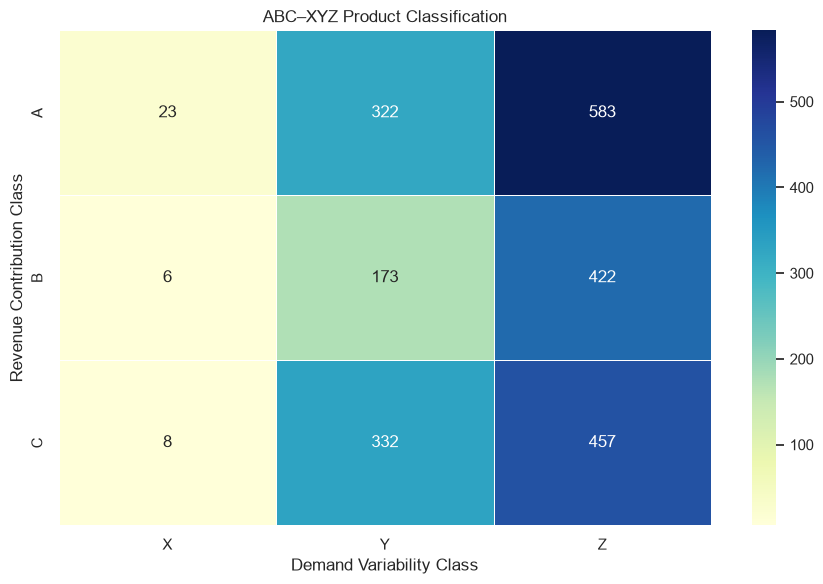

In [30]:
fig, ax = plt.subplots(figsize=(9, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=0.5,
    ax=ax
)

ax.set_title("ABC–XYZ Product Classification")
ax.set_xlabel("Demand Variability Class")
ax.set_ylabel("Revenue Contribution Class")

plt.tight_layout()

plt.savefig(
    IMAGES_DIR / "abc_xyz_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()